# Lesson 01 — Descriptive Statistics and Distributions

> **Data:** `../data/customers.csv` (800 SaaS customers) &nbsp;·&nbsp; **Time:** ~90 min &nbsp;·&nbsp; **Needs:** Modules 01–02

## What you will be able to do

By the end of this notebook you can:

1. **Tell numerical from categorical data** and explain why that single distinction
   decides every method you are allowed to use later.
2. **Summarise centre and spread** — mean, median, mode, range, variance, standard
   deviation, quartiles, IQR — and say which one to trust when.
3. **Read skew from the mean–median gap** without plotting anything.
4. **Flag outliers with the 1.5 × IQR fence**, and decide whether to keep them.
5. **Turn counts into probabilities**, and apply the addition and multiplication rules.
6. **Use four named distributions** — uniform, binomial, normal, exponential — and the
   three functions that make them useful: `cdf` (what fraction below),
   `sf` (what fraction above), `ppf` (what value at percentile *p*).

## The one idea to hold on to

Every summary statistic **throws information away on purpose**. The mean throws away
the shape; the median throws away the magnitude of the extremes. Knowing what each one
discards is knowing when it will mislead you.

# Introduction to Statistics

## Table for Statistical Concepts

| Concept | What it means | How to interpret it | Quick rule / tip | Python example |
|---|---|---|---|---|
| **Mean** | Average of all values | Shows the overall center of the data | Sensitive to outliers | `df['col'].mean()` |
| **Median** | Middle value after sorting | Better center when data is skewed | Use when there are outliers | `df['col'].median()` |
| **Mode** | Most frequent value | Useful for repeated or categorical values | A dataset can have more than one mode | `df['col'].mode()` |
| **Minimum** | Smallest value | Shows lower bound of the data | Check if it looks unusually low | `df['col'].min()` |
| **Maximum** | Largest value | Shows upper bound of the data | Check if it looks unusually high | `df['col'].max()` |
| **Range** | Difference between max and min | Measures total spread | Very sensitive to extreme values | `df['col'].max() - df['col'].min()` |
| **Variance** | Average squared distance from the mean | Higher variance = more spread out data | Harder to interpret because units are squared | `df['col'].var()` |
| **Standard Deviation** | Typical distance from the mean | Higher std = more variability | Easier to understand than variance | `df['col'].std()` |
| **`ddof`** | Delta Degrees of Freedom used in variance/std calculation | Controls divisor in formula | `ddof=0` for population, `ddof=1` for sample | `df['col'].std(ddof=1)` |
| **Population Std / Var** | Spread using all data points as the full population | Assumes you have the complete data | Divides by `n` | `df['col'].std(ddof=0)` |
| **Sample Std / Var** | Spread estimated from sample data | Better when data is only a sample | Divides by `n-1` | `df['col'].std(ddof=1)` |
| **Skewness** | Measures asymmetry of the distribution | Positive = right tail, negative = left tail | Near 0 means roughly symmetric | `df['col'].skew()` |
| **Positive Skew** | Long tail on the right | A few large values pull data upward | Usually `mean > median` | Check with mean and median |
| **Negative Skew** | Long tail on the left | A few small values pull data downward | Usually `mean < median` | Check with mean and median |
| **Skewness Rule of Thumb** | Guideline for shape | `-0.5 to 0.5`: roughly symmetric; `0.5 to 1` or `-0.5 to -1`: moderate skew; beyond `1` or `-1`: high skew | Use as guide, not strict rule | — |
| **Kurtosis** | Measures tail heaviness / extreme values | High kurtosis = more extreme values/outliers | Useful together with boxplot/histogram | `df['col'].kurt()` |
| **Quartiles** | Values dividing data into 4 parts | Q1 = 25%, Q2 = 50%, Q3 = 75% | Q2 is the median | `df['col'].quantile([0.25,0.5,0.75])` |
| **IQR** | Interquartile Range = Q3 - Q1 | Spread of middle 50% of data | Good for outlier detection | `df['col'].quantile(0.75) - df['col'].quantile(0.25)` |
| **Percentile** | Value below which a percentage of data falls | Example: 90th percentile means 90% of values are below it | Useful for rankings and thresholds | `np.percentile(df['col'], 90)` |
| **z-score** | Number of standard deviations from the mean | Large positive/negative values may be unusual | Common outlier check: \|z\| > 3 | `(x - mean) / std` |
| **Standard Error (SE)** | Measures how much a sample mean may vary | Smaller SE = more stable sample mean | Increases with variability, decreases with larger sample size | `df['col'].std()/np.sqrt(len(df['col']))` |
| **Confidence Interval** | Plausible range for a population parameter | Narrower interval = more precise estimate | Often reported as 95% CI | Usually from statistical libraries |
| **Correlation** | Strength and direction of linear relationship between two variables | Near +1 = strong positive, near -1 = strong negative, near 0 = weak/no linear relation | Correlation does not mean causation | `df[['x','y']].corr()` |
| **Outlier** | A value much smaller or larger than others | Can affect mean, std, skewness, and models | Use boxplot, IQR, or z-score to check | — |

## Very Quick Interpretation Table

| Situation | Likely meaning |
|---|---|
| **Mean > Median** | Data may be positively skewed |
| **Mean < Median** | Data may be negatively skewed |
| **Mean ≈ Median** | Data may be roughly symmetric |
| **High standard deviation** | Data is widely spread |
| **Low standard deviation** | Data is tightly clustered |
| **Skewness near 0** | Distribution is roughly symmetric |
| **Skewness > 0** | Right-skewed distribution |
| **Skewness < 0** | Left-skewed distribution |
| **High kurtosis** | More extreme values / heavier tails |
| **Large IQR** | Middle 50% is more spread out |
| **`ddof=0`** | Treating data as full population |
| **`ddof=1`** | Treating data as a sample |

## Python Summary Block

```python
import numpy as np
import pandas as pd

s = df['col']

print("Mean:", s.mean())
print("Median:", s.median())
print("Mode:", s.mode())
print("Min:", s.min())
print("Max:", s.max())
print("Range:", s.max() - s.min())
print("Variance (sample):", s.var(ddof=1))
print("Std (sample):", s.std(ddof=1))
print("Std (population):", s.std(ddof=0))
print("Skewness:", s.skew())
print("Kurtosis:", s.kurt())
print("Quartiles:")
print(s.quantile([0.25, 0.50, 0.75]))
print("IQR:", s.quantile(0.75) - s.quantile(0.25))
print("90th Percentile:", np.percentile(s.dropna(), 90))

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import statistics
import scipy.stats as stats
from scipy.stats import norm, uniform, binom, poisson, expon, t as t_dist, gaussian_kde
import numpy as np

## Types of data 

### Numerical (Quantitative)

- continuos data -> any value in a range - 127.3cm
- discrete data -> specific countable value - 1,2,3

### Categorical (Qualitative)

- nominal data - categories without any order -  unrank
- Ordinal data - meaningful order - primary, secondary -rank

- data science connection
- numeric continuos - standardScaler, histograms, correlation
- numeric discrete - count models, poisson regression
- categorical nominal - OneHotEncoder , chi-square tests
- categorical ordinal - OrdinalEncoder , rank based methods

In [2]:
df = pd.read_csv('../../00-data/customers.csv', index_col=0)
df.head()

,company_name,plan_tier,industry,team_size,monthly_spend,avg_session_min,support_tickets,satisfaction_score
0,Client 0001,Starter,Technology,13,119.50,25.6,4,Passive
1,Client 0002,Starter,Education,7,119.34,41.3,3,Detractor
2,Client 0003,Growth,Technology,34,324.85,29.1,2,Promoter
3,Client 0004,Starter,Healthcare,9,133.59,8.7,5,Passive
4,Client 0005,Starter,Technology,9,55.38,32.5,6,Promoter


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 800 entries, 0 to 799
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   company_name        800 non-null    object 
 1   plan_tier           800 non-null    object 
 2   industry            800 non-null    object 
 3   team_size           800 non-null    int64  
 4   monthly_spend       800 non-null    float64
 5   avg_session_min     800 non-null    float64
 6   support_tickets     800 non-null    int64  
 7   satisfaction_score  800 non-null    object 
dtypes: float64(2), int64(2), object(4)
memory usage: 56.2+ KB


In [4]:
for col in df.columns:
    unique_vals = df[col].unique()
    display_vals = unique_vals[:5] if len(unique_vals) > 5 else unique_vals
    print(f"Columns: {col}")
    print(f'dtype: {df[col].dtype}')
    print(f'unique: {len(unique_vals)} values')
    print(f"Sample: {display_vals}")
    print("*"*100)

Columns: company_name
dtype: object
unique: 800 values
Sample: ['Client 0001' 'Client 0002' 'Client 0003' 'Client 0004' 'Client 0005']
****************************************************************************************************
Columns: plan_tier
dtype: object
unique: 3 values
Sample: ['Starter' 'Growth' 'Enterprise']
****************************************************************************************************
Columns: industry
dtype: object
unique: 5 values
Sample: ['Technology' 'Education' 'Healthcare' 'Retail' 'Finance']
****************************************************************************************************
Columns: team_size
dtype: int64
unique: 195 values
Sample: [ 13   7  34   9 219]
****************************************************************************************************
Columns: monthly_spend
dtype: float64
unique: 793 values
Sample: [119.5  119.34 324.85 133.59  55.38]
**********************************************************************

In [5]:
df.describe()['monthly_spend']

count     800.000000
mean      547.871150
std       775.493587
min        39.530000
25%       118.732500
50%       230.460000
75%       581.377500
max      7539.930000
Name: monthly_spend, dtype: float64

<Axes: ylabel='Frequency'>

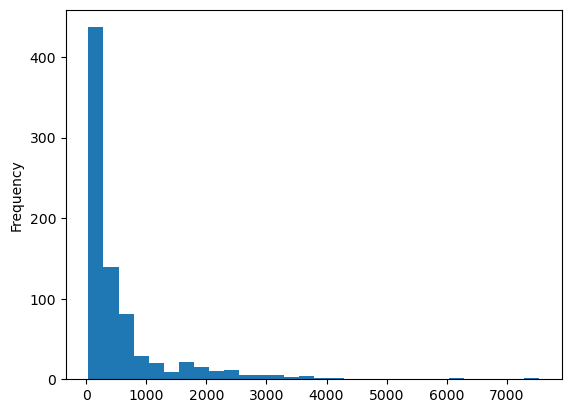

In [6]:
df['monthly_spend'].plot(kind='hist',bins=30)

In [7]:
range_spend = df['monthly_spend'].max() - df['monthly_spend'].min()
range_spend

7500.400000000001

In [8]:
var_spend = np.var(df['monthly_spend'],ddof=0) # ddof 0 means population data
var_spend

600638.5657534268

In [9]:
np.var(df['monthly_spend'],ddof=1) # ddof 1 means sample data

601390.3036329679

population data
sample data

In [10]:
monthly_var = df['monthly_spend'].var()
monthly_var

601390.3036329679

In [11]:
np.sqrt(monthly_var)

np.float64(775.493587099834)

In [12]:
df['monthly_spend'].std()

775.493587099834

![](https://blog.alliedoffsets.com/hs-fs/hubfs/0_oKdGBtBV6iJDookJ.webp?width=2800&height=1400&name=0_oKdGBtBV6iJDookJ.webp)

In [13]:
q1 = np.quantile(df['monthly_spend'],0.25)
q2 = np.quantile(df['monthly_spend'],0.50)
q3 = np.quantile(df['monthly_spend'],0.75)

In [14]:
q1,q2,q3

(np.float64(118.73249999999999), np.float64(230.46), np.float64(581.3775))

In [15]:
import seaborn as sns

<Axes: xlabel='monthly_spend'>

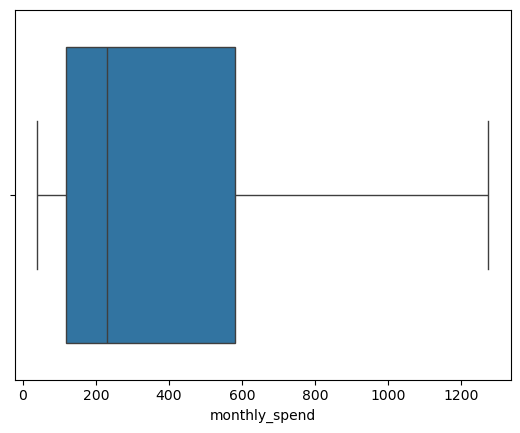

In [16]:
sns.boxplot(data=df,x='monthly_spend',showfliers=False)

In [17]:
iqr_spend = stats.iqr(df['monthly_spend'])
iqr_spend

np.float64(462.6450000000001)

In [18]:
lower_bound = q1 - 1.5*iqr_spend
upper_bound = q3 + 1.5*iqr_spend
lower_bound,upper_bound

(np.float64(-575.2350000000002), np.float64(1275.3450000000003))

In [19]:
outliers = (df['monthly_spend']<lower_bound)|(df['monthly_spend']> upper_bound)
outliers = df[outliers]
outliers

,company_name,plan_tier,industry,team_size,monthly_spend,avg_session_min,support_tickets,satisfaction_score
5,Client 0006,Enterprise,Healthcare,219,1848.47,23.3,1,Promoter
8,Client 0009,Enterprise,Retail,324,2519.69,24.1,2,Promoter
28,Client 0029,Enterprise,Technology,186,1674.84,19.6,1,Promoter
38,Client 0039,Enterprise,Retail,265,1682.99,38.2,3,Passive
49,Client 0050,Enterprise,Healthcare,24,2084.91,37.5,7,Promoter
...,...,...,...,...,...,...,...,...
707,Client 0708,Enterprise,Technology,190,1669.82,29.9,1,Detractor
711,Client 0712,Enterprise,Technology,264,1839.93,37.1,0,Detractor
716,Client 0717,Enterprise,Retail,255,1854.10,24.3,3,Passive
771,Client 0772,Enterprise,Healthcare,302,1779.74,38.4,2,Passive


<Axes: xlabel='monthly_spend', ylabel='monthly_spend'>

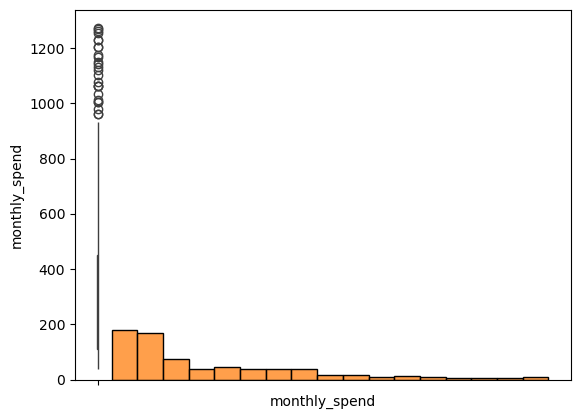

In [20]:
without_outliers = (df['monthly_spend']>=lower_bound)&(df['monthly_spend']<= upper_bound)
no_outliers = df[without_outliers]
sns.boxplot(no_outliers['monthly_spend'])
sns.histplot(no_outliers['monthly_spend'])

<Axes: xlabel='monthly_spend', ylabel='Density'>

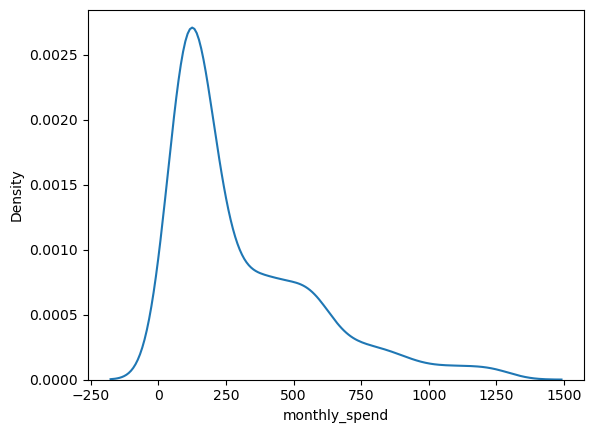

In [21]:
sns.kdeplot(no_outliers['monthly_spend'])

In [22]:
no_outliers.columns

Index(['company_name', 'plan_tier', 'industry', 'team_size', 'monthly_spend',
       'avg_session_min', 'support_tickets', 'satisfaction_score'],
      dtype='object')

<Axes: xlabel='avg_session_min'>

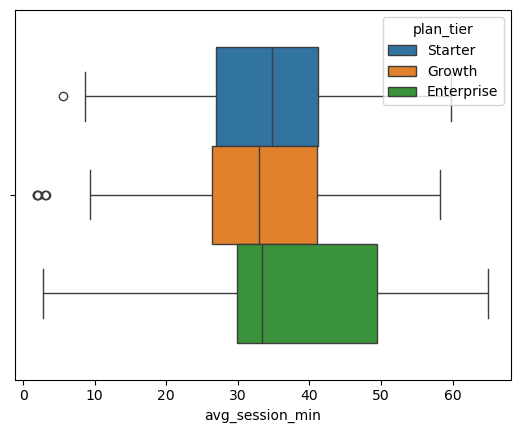

In [23]:
sns.boxplot(no_outliers,x='avg_session_min',hue='plan_tier')

<Axes: xlabel='avg_session_min'>

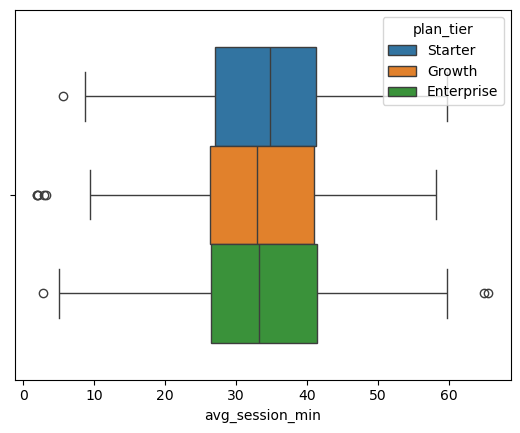

In [24]:
sns.boxplot(df,x='avg_session_min',hue='plan_tier')

![](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Ffile.forms.app%2Fsitefile%2Fd-s-m-27.jpeg&f=1&nofb=1&ipt=50df0edaefd525d8290e8b0aa349a0b5db62afcc500871d20d3ed5c67c7ea28d)

## Probability Fundamentals

In [25]:
df.head(2)

,company_name,plan_tier,industry,team_size,monthly_spend,avg_session_min,support_tickets,satisfaction_score
0,Client 0001,Starter,Technology,13,119.50,25.6,4,Passive
1,Client 0002,Starter,Education,7,119.34,41.3,3,Detractor


![](https://miro.medium.com/1*eff8FUgdX-PRH4yZk_vtCw.jpeg)
- A/B Testing: "Is this conversion rate diffence real or just noise"
- Classification: 'What is the prob this customer will pay for the next tier'
- Risk Assessements: "What is the chance our server has >5 errors in an hour"

### Key Rules
| Rule | Formula |
|---|---|
| Probability range | $0 \le P(A) \le 1$ |
| Complement | $P(\text{not } A) = 1 - P(A)$ |
| Independent events | $P(A \text{ and } B) = P(A) \times P(B)$ |

In [26]:
n_total = len(df)

# P(customer is on ent plan) 
n_ent = len(df[df['plan_tier']=='Enterprise'])
p_ent = n_ent/n_total
p_ent

# P(Customer filed 0 support tickets this month) 
n_zero_tickets = len(df[df['support_tickets']==0])
p_zero = n_zero_tickets/n_total
p_zero

# Complement: P(NOT Free)
n_free = len(df[df['plan_tier']=='Free'])
p_not_free = 1 - (n_free/n_total)
p_not_free

1.0

## Random Sampling and the Law of Large Numbers

- LLN : As sample size increases, the sample mean converges to the population mean
    -- more data = better models

In [27]:
pop_mean = np.mean(df['support_tickets'])
pop_mean

np.float64(2.43)

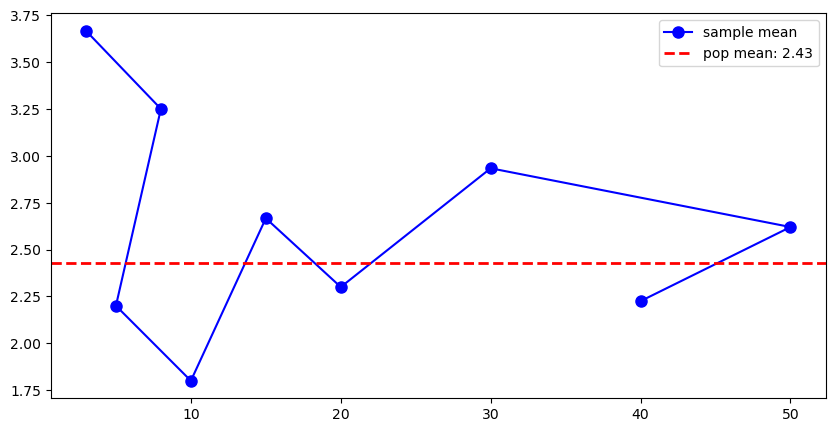

In [28]:
np.random.seed(12)
sample_sizes = [3,8,5,10,15,20,30,50,40]
sample_means = []

for n in sample_sizes:
    sample = np.random.choice(df['support_tickets'],size=n, replace=False)
    sample_means.append(np.mean(sample))

plt.figure(figsize=(10,5))
plt.plot(sample_sizes,sample_means,'bo-',markersize=8,label='sample mean')
plt.axhline(y=pop_mean,linewidth=2,label=f'pop mean: {pop_mean:.2f}',color='red',linestyle='--')
plt.legend()
plt.show()

### Continous Distrbutions: Uniform Dist
- A random var is uniformly distributed when all values are in range which is equally likely

- Support chat queue opens at the top of each hour. Customers arrive at random times, uniformly distributed over 60 minute window. What is the prob a customer arrives in first 15 minutes?

In [29]:
p_first_15 = uniform.cdf(15,loc=0,scale=60)
p_first_15

np.float64(0.25)

In [30]:
# P(Arrival between 20 and 40)
# we want P(20 <= arrival <= 40)
uniform.cdf(40,0,60) - uniform.cdf(20,0,60)

np.float64(0.3333333333333333)

In [31]:
# P(arrival in the last 10 minutes)
1 - uniform.cdf(50,0,60)

np.float64(0.16666666666666663)

In [32]:
uniform.sf(50,0,60)

np.float64(0.16666666666666663)

In [33]:
### generate some random arrival time 
random_arrival = uniform.rvs(loc=0,scale=60,size=10)
random_arrival

array([19.16623453, 46.65067151, 30.00922011, 23.08486248, 43.3363242 ,
        8.21605931,  5.76387905, 18.74310838,  0.59081265, 33.41189296])

In [34]:
# x = np.sort(random_arrival)
# y = np.arange(1,len(x)+1) / len(x)

# plt.step(x,y)

## Discrete Distribution: Binomial Distribution

n = numbers of trials
p = prob of success per trial

In [35]:
n_trials = 25
p_conv = 0.12

expected = n_trials*p_conv
expected

3.0

In [36]:
# p(exactly 3 conversion)
binom.pmf(3,n_trials,p_conv)

np.float64(0.23872085511238475)

In [37]:
# p(atleast 5 conversion)
binom.sf(4,n_trials,p_conv)

np.float64(0.1734223119351001)

In [38]:
# p(zero conversion)abs
binom.pmf(0,n_trials,p_conv)


np.float64(0.04093236175904466)

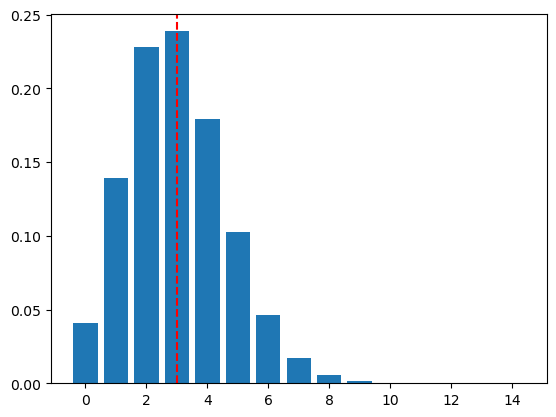

In [39]:
k_values = np.arange(0,15)
pmf_values = binom.pmf(k_values,n_trials,p_conv)
plt.bar(k_values,pmf_values)
plt.axvline(expected,color='red',linestyle='--')

## The normal dist

![](https://www.scribbr.de/wp-content/uploads/2023/01/Standard-normal-distribution.webp)
![](https://ledidi.com/uploads/icons/median-mode-mean-central-dendency-ledidi-academy.png)

In [40]:
sess_mean = np.mean(df['avg_session_min'])
sess_mean

np.float64(33.81825)

In [41]:
sess_std = np.std(df['avg_session_min'],ddof=1)
sess_std

10.76253255843341

In [42]:
# P(session < 20)
norm.cdf(20,loc=sess_mean,scale=sess_std)

np.float64(0.09958466217478773)

In [43]:
# P(session > 50)
norm.sf(50,loc=sess_mean,scale=sess_std)

np.float64(0.06635169913267017)

In [44]:
# what session duration is the 90th percentile? 
norm.ppf(0.90,loc=sess_mean,scale=sess_std)

np.float64(47.61099044948507)

In [45]:
# what session duration is the 10th percentile? 
norm.ppf(0.10,loc=sess_mean,scale=sess_std)

np.float64(20.02550955051493)

### Exponential Distribution

![](https://media.geeksforgeeks.org/wp-content/uploads/20250531112201235467/download.png)

In [46]:
# if server errors occurs at 2.5 per hour, how long between errors on average

mean_wait = 1/2.5
# mean_wait # 24 minutes
mean_wait_min = mean_wait*60
lamda_error = 2.5
print(f"Average time between errors: {mean_wait} hours ({mean_wait_min}) minutes")

Average time between errors: 0.4 hours (24.0) minutes


In [47]:
# P(next error within 10 minutes)
expon.cdf(10/60,scale=mean_wait)

np.float64(0.3407593697995563)

In [48]:
# p(error-free for more than 1 hour)
expon.sf(1,scale=mean_wait)

np.float64(0.0820849986238988)

In [49]:
# p(error between 15 and 30 min)


---

# How this is used in data science and machine learning

Descriptive statistics is not a warm-up before the real work. Every item below is a
decision you will make in the first hour of a modelling project.

### 1. `describe()` is your first bug report
Before any model, you run `df.describe()` and read it adversarially. A `min` of `-1` on
an age column, a `max` of `999999` on income, a standard deviation of `0` on a feature
that is supposed to vary — these are data collection bugs, and they are cheaper to find
now than after a model has silently learned them.

### 2. The mean–median gap decides whether you transform a feature
A large gap means skew. Linear and distance-based models (linear/logistic regression,
SVM, k-NN, k-means, PCA) assume roughly symmetric, comparably-scaled inputs, so a skewed
feature usually gets a `log1p` transform before it goes in. Tree-based models
(Random Forest, XGBoost) split on order alone and do not care — **which model you plan to
fit changes whether this step is necessary at all.**

### 3. The IQR fence is outlier clipping in a pipeline
The `q1 - 1.5*iqr` / `q3 + 1.5*iqr` calculation is exactly what a preprocessing step does
when it winsorises a feature. It is also why `sklearn.preprocessing.RobustScaler` exists:
it centres on the **median** and scales by the **IQR** instead of the mean and standard
deviation, so a handful of extreme rows cannot drag the scaling of the whole column.

### 4. Standard deviation is what `StandardScaler` divides by
`StandardScaler` computes `(x - mean) / std`. That is this notebook's formula, applied per
column. Two consequences worth remembering:
- The scaler must be **fitted on the training set only**, then applied to the test set.
  Fitting on everything leaks test information into training.
- `ddof` matters: `numpy` defaults to the population formula (`ddof=0`), `pandas` to the
  sample formula (`ddof=1`). They disagree, and on small samples the disagreement is visible.

### 5. `norm.ppf` is the engine inside every confidence interval
When you see `1.96` in an interval, that is `norm.ppf(0.975)`. The same function converts
any confidence level into its multiplier, which is what Lesson 02 builds on.

### 6. Distributions tell you which assumption you are about to break
| Distribution | Where it shows up in DS/ML |
|---|---|
| **Normal** | Residual assumptions in linear regression; the sampling distribution of almost any mean, via the CLT |
| **Binomial** | Conversion, click-through, churn — any yes/no outcome; the likelihood behind logistic regression |
| **Poisson / Exponential** | Event counts and waiting times; arrivals, failures, request latency |
| **Uniform** | Random initialisation, random search over hyperparameters, simulation |

### 7. This whole notebook is the EDA step of CRISP-DM
"Data Understanding" is not a formality. A feature you have not looked at is a feature you
cannot debug when the model behaves strangely six weeks from now.